<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG101 - Fundamentos de Estadística**</span>

Bienvenido al curso!!!

Vamos a revisar las bases de la <span style="color:gold">estadística</span> usando ejemplos en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python y visualización de datos con Matplotlib.


<span style="color:gold; font-size:20px">**Probabilidades** </span>

***
- [Conceptos básicos de probabilidad](#parte-1)
- [Reglas de Suma y Producto](#parte-2)
- [Teorema de Bayes](#parte-3)
- [En conclusión...](#parte-4)

***

In [ ]:
import sys
# Preparación del entorno del navegador.
if sys.platform == 'emscripten':
    import piplite
    await piplite.install(['matplotlib'])

<a id="parte-1"></a>

### <span style="color:lightgreen">**Conceptos básicos de probabilidad** </span>
***

<span style="color:gold">**Experimento aleatorio** </span>

Un experimento aleatorio es un proceso que produce resultados impredecibles. En el contexto de la geología, un ejemplo de experimento aleatorio podría ser la toma de muestras de diferentes litologías en una zona específica.

Para ilustrar este concepto, crearemos una función que simula la acción de **tomar una muestra del campo y determinar su litología**.



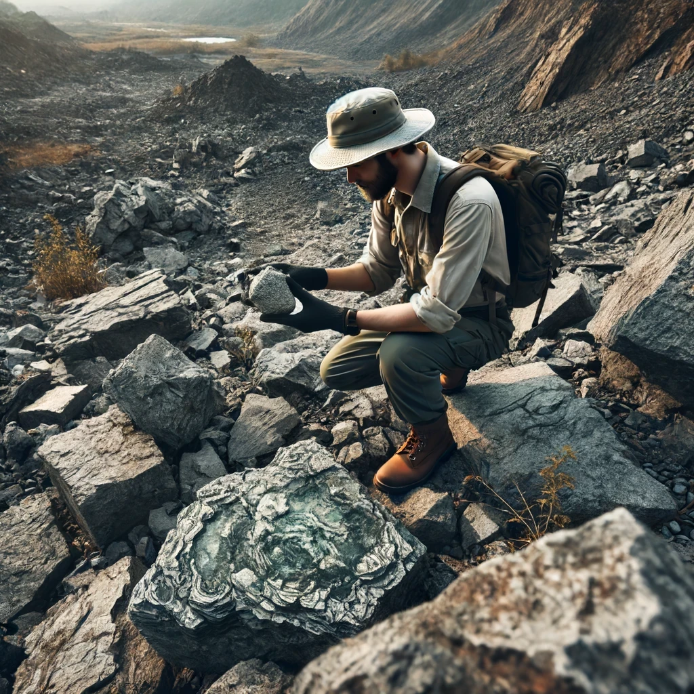



La función `tomar_muestra` seleccionará aleatoriamente un tipo de roca de una lista predefinida de litologías, representando así el experimento aleatorio.

Para esto, usaremos un <span style="color:gold">espacio muestral</span>, que representa el conjunto de todos los posibles resultados en un experimento aleatorio.

En este modelo las seis etiquetas son equiprobables y cada extracción se hace con reemplazo. Es una decisión de simulación, no una afirmación sobre abundancias reales en campo.

In [ ]:
import numpy as np
np.random.seed(42) # Secuencia reproducible para el ejemplo.

> La función de Numpy, `random.choice`, elige aleatoriamente un elemento dentro de una lista.

In [ ]:
# Espacio muestral con diferentes litologías
espacio_muestral = ["Basalto", "Andesita", "Granito", "Caliza", "Arenisca", "Lutita"]

# Definimos el experimento aleatorio
def tomar_muestra():
    muestra = np.random.choice(espacio_muestral) # Selecciona aleatoriamente una muestra
    return muestra

Con esta función, podemos reproducir el experimento y obtener muestras aleatorias de diferentes rocas:

In [ ]:
# Extrae una muestra de la población
muestra = tomar_muestra()
print(f"Muestra extraída: {muestra}")

Si repetimos el experimento varias veces, obtendremos diferentes tipos de rocas, ilustrando la variabilidad y aleatoriedad del proceso:

In [ ]:
# Repetir el experimento 10 veces
for i in range(10):
    muestra = tomar_muestra()
    print(f"Muestra extraída: {muestra}")

Un <span style="color:gold">evento</span> es cualquier subconjunto del espacio muestral. Por ejemplo, un evento podría ser encontrar una roca ígnea (`Basalto`, `Andesita` o `Granito`).

In [ ]:
# Repetir el experimento 10 veces
for i in range(10):
    muestra = tomar_muestra()
    # Evaluar si la muestra es de roca ígnea
    if muestra in ["Basalto", "Andesita", "Granito"]:
        print(f"Muestra extraída: {muestra} (ígnea)")
    else:
        print(f"Muestra extraída: {muestra} (no ígnea)")

***
<span style="color:gold">**Probabilidad**</span>

La probabilidad es una medida de la frecuencia con la que ocurre un evento, calculada como el número de resultados favorables dividido por el número total de resultados posibles.

En términos matemáticos, si $E$ es un evento y $S$ es el espacio muestral, la probabilidad de $E$ se define como:



$$
\large
P(E) =
\frac
{Número\space de\space resultados\space favorables}
{Número\space total\space de\space resultados\space del\space espacio\space muestral}
$$



<br>
Vamos a calcular las probabilidades de cada tipo de roca, para esto repetiremos el experimento muchas veces y almacenaremos los resultados en una lista:

La razón de casos favorables/posibles se aplica directamente cuando los resultados elementales son equiprobables. Una frecuencia observada estima una probabilidad; no es su definición general.

In [ ]:
# Repetir el experimento 1,000 veces
total = []
for i in range(1_000):
    muestra = tomar_muestra()
    total.append(muestra)

In [ ]:
# Iterar en el espacio muestral
for roca in espacio_muestral:
    conteo = total.count(roca)
    # Calcular las probabilidades
    probabilidad = conteo / len(total)
    print(f"{roca}: {probabilidad:.1%}")

Notamos que las frecuencias observadas para cada tipo de roca son diferentes. Teóricamente, la probabilidad debería ser la misma para cada litología y sería igual a $1/6$ en fracción o $16.666\%$ en porcentaje.

Si repetimos el experimento muchas veces más, deberíamos obtener un resultado más cercano a la probabilidad teórica:

In [ ]:
# Repetir el experimento 10,000 veces
total = []
for i in range(10_000):
    muestra = tomar_muestra()
    total.append(muestra)

In [ ]:
# Iterar en el espacio muestral
for roca in espacio_muestral:
    conteo = total.count(roca)
    # Calcular las probabilidades
    probabilidad = conteo / len(total)
    print(f"{roca}: {probabilidad:.1%}")

Notamos que las probabilidades de cada litología se acercan bastante a la probabilidad teórica. Esto se debe a la <span style="color:gold">Ley de los grandes números</span>.

> La **Ley de los Grandes Números** es un teorema fundamental en la teoría de la probabilidad que establece que a medida que el número de ensayos o muestras independientes de un experimento aleatorio aumenta, la media aritmética de los resultados observados se aproxima a la esperanza matemática (valor esperado) de la variable aleatoria.

***

### <span style="color:gold">**Frecuencia observada y probabilidad del modelo**</span>

La curva utiliza la misma secuencia acumulada de extracciones. ¿Debe acercarse al valor teórico en cada paso? No: puede alejarse temporalmente, aunque el promedio se estabilice.

In [ ]:
import matplotlib.pyplot as plt
indicador = np.array(total) == 'Basalto'
ensayos = np.arange(1, len(indicador)+1)
frecuencia_acumulada = np.cumsum(indicador) / ensayos
fig, eje = plt.subplots(figsize=(9, 3.8))
eje.plot(ensayos, frecuencia_acumulada, color='#0072B2', label='Frecuencia acumulada de Basalto')
eje.axhline(1/6, color='#D55E00', ls='--', label='Probabilidad del modelo = 1/6')
eje.set(xscale='log', xlabel='Número de extracciones (escala logarítmica)', ylabel='Proporción',
        title='La convergencia no es monótona', ylim=(0, 1))
eje.legend()
fig.tight_layout()
plt.show()

<a id="parte-2"></a>

### <span style="color:lightgreen">**Reglas de Suma y Producto**</span>
***

<span style="color:gold">**Regla de la suma**</span>

Si dos eventos son mutuamente excluyentes (es decir, **no pueden ocurrir al mismo tiempo**), la probabilidad de que ocurra uno u otro es la suma de sus probabilidades.

Al extraer una muestra de una litología, no es posible obtener simultáneamente otra litología en la misma muestra. Por lo tanto, la probabilidad de extraer una litología es mutuamente excluyente de las demás.

In [ ]:
# Probabilidades de cada litología
P_basalto = 1/6
P_andesita = 1/6
P_granito = 1/6
P_caliza = 1/6
P_arenisca = 1/6
P_lutita = 1/6

In [ ]:
# Probabilidad de obtener granito o basalto
P_granito_o_basalto = P_granito + P_basalto
print(f"Probabilidad de encontrar Granito o Basalto: {P_granito_o_basalto:.0%}")

In [ ]:
# Probabilidad de obtener cualquier tipo de litología
P_cualquier_litologia = P_basalto + P_andesita + P_granito + P_caliza + P_arenisca + P_lutita
print(f"Probabilidad de encontrar cualquier tipo de litología: {P_cualquier_litologia:.0%}")

***
<span style="color:gold">**Regla del producto** </span>

Si dos eventos son independientes (es decir, **la ocurrencia de uno no afecta la ocurrencia del otro**), la probabilidad de que ambos ocurran es el producto de sus probabilidades.

Al extraer dos muestras, la ocurrencia de un evento en una muestra no afecta la ocurrencia del mismo evento en la otra muestra.

La independencia es una hipótesis del experimento. Muestras cercanas o extracciones sin reemplazo pueden depender unas de otras; en general P(A y B)=P(A)P(B|A).

In [ ]:
# Intentar extraer una muestra de Arenisca
# Probabilidad: 16.666 %
print(f"Probabilidad de extraer 1 muestra de Arenisca: {P_arenisca:.2%}")
print(tomar_muestra())

In [ ]:
# Intentar extraer dos muestras de Arenisca
# Probabilidad: 16.666 % x 16.666 %
P_2_areniscas = P_arenisca * P_arenisca
print(f"Probabilidad de extraer 2 muestras de Arenisca: {P_2_areniscas:.2%}")
print(tomar_muestra()) # Primer experimento
print(tomar_muestra()) # Segundo experimento (independiente del primero)

In [ ]:
# Intentar extraer tres muestras de Arenisca
# Probabilidad: 16.666 % x 16.666 % x 16.666 %
P_3_areniscas = P_arenisca * P_arenisca * P_arenisca
print(f"Probabilidad de extraer 3 muestras de Arenisca: {P_3_areniscas:.2%}")
print(tomar_muestra()) # Primer experimento
print(tomar_muestra()) # Segundo experimento
print(tomar_muestra()) # Tercer experimento

<a id="parte-3"></a>

### <span style="color:lightgreen">**Teorema de Bayes**</span>
***

<span style="color:gold">**Probabilidad condicional**</span>

La probabilidad condicional es la probabilidad de que ocurra un evento dado que otro evento ya ha ocurrido.

In [ ]:
# Probabilidad de una primera extracción de basalto
print(f'Probabilidad de extraer Basalto: {P_basalto:.2%}')

In [ ]:
# Segunda extracción independiente: condicional frente a conjunta
P_segunda_dado_basalto = P_granito + P_arenisca
P_conjunta = P_basalto * P_segunda_dado_basalto
print(f'P(Granito o Arenisca en la segunda | Basalto en la primera): {P_segunda_dado_basalto:.2%}')
print(f'P(Basalto primero y Granito o Arenisca después): {P_conjunta:.2%}')

<span style="color:gold">**Teorema de Bayes**</span>

El Teorema de Bayes proporciona una manera de actualizar las probabilidades de un evento basándose en nueva información.

Es particularmente útil en situaciones donde queremos ajustar nuestras creencias iniciales (probabilidades a priori) con evidencia adicional (probabilidades condicionales).

La fórmula del Teorema de Bayes es:



$$
\Large P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}
$$



Donde:

- $P(A|B)$: es la probabilidad de que ocurra el evento 𝐴 dado que ocurrió el evento 𝐵 (probabilidad a posteriori).
- $P(B|A)$: es la probabilidad de que ocurra el evento 𝐵 dado que ocurrió el evento 𝐴.
- $P(A)$: es la probabilidad de que ocurra el evento 𝐴 (probabilidad a priori).
- $P(B)$: es la probabilidad de que ocurra el evento 𝐵.

***
**Ejemplo: Identificación de un Mineral**

Supongamos que estamos explorando una zona y sabemos que hay dos tipos de formaciones geológicas: Formaciones A y B. La formación A contiene un 40% de cuarzo y la formación B contiene un 20% de cuarzo. Además, sabemos que la formación A es el 60% de la zona de estudio y la formación B es el 40% restante.

Queremos calcular la probabilidad de que una muestra provenga de la formación A si se encontró cuarzo en la muestra.

Interpretaremos 40% y 20% como probabilidades de detectar cuarzo en una muestra de cada formación. Una proporción modal de mineral no equivale automáticamente a esa probabilidad: hace falta un modelo de muestreo.

In [ ]:
# Probabilidades iniciales
P_A = 0.60 # Probabilidad de que la muestra pertenezca a la formación A
P_B = 0.40 # Probabilidad de que la muestra pertenezca a la formación B
P_cuarzo_dado_A = 0.40 # Probabilidad de que la muestra contenga cuarzo dado que proviene de la formación A
P_cuarzo_dado_B = 0.20 # Probabilidad de que la muestra contenga cuarzo dado que proviene de la formación B

Empezaremos calculando la probabilidad de encontrar cuarzo (en toda la zona de estudio):

In [ ]:
# Calcular P(cuarzo)
P_cuarzo = (P_cuarzo_dado_A * P_A) + (P_cuarzo_dado_B * P_B)
print(f"Probabilidad total de encontrar cuarzo: {P_cuarzo:.0%}")

Usamos la fórmula del Teorema de Bayes para calcular $P(A|cuarzo)$:

In [ ]:
# Calcular P(A|cuarzo) usando el Teorema de Bayes
P_A_dado_cuarzo = (P_cuarzo_dado_A * P_A) / P_cuarzo
print(f"Probabilidad de que la muestra provenga de la formación A dado que se encontró cuarzo: {P_A_dado_cuarzo:.0%}")

### <span style="color:gold">**Bayes con 1000 muestras hipotéticas**</span>

Multiplica las probabilidades por 1000: 600 muestras provienen de A y 400 de B. Se espera detectar cuarzo en 240 de A y 80 de B. Entre las 320 positivas, ¿qué parte proviene de A? Estas son frecuencias esperadas del modelo, no datos observados.

In [ ]:
esperadas = np.array([[240, 360], [80, 320]])
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
ejes[0].bar(['A', 'B'], esperadas[:,0], color='#0072B2', label='Con cuarzo')
ejes[0].bar(['A', 'B'], esperadas[:,1], bottom=esperadas[:,0], color='#cccccc', label='Sin cuarzo')
for i, valores in enumerate(esperadas):
    ejes[0].text(i, valores[0]/2, str(valores[0]), ha='center', color='white')
ejes[0].set(title='Todas las muestras hipotéticas', ylabel='Número esperado de muestras', xlabel='Formación')
ejes[0].legend()
ejes[1].bar(['A', 'B'], esperadas[:,0], color=['#0072B2', '#D55E00'])
ejes[1].set(title=f'Solo con cuarzo: P(A|cuarzo)={P_A_dado_cuarzo:.0%}',
            ylabel='Número esperado con cuarzo', xlabel='Formación')
ejes[1].set_ylim(0, 270)
for i, valor in enumerate(esperadas[:,0]):ejes[1].text(i, valor+5, str(valor), ha='center')
fig.tight_layout()
plt.show()

Bayes cambia el grupo de referencia: de las 1000 muestras pasamos a las 320 positivas. P(cuarzo|A)=40% y P(A|cuarzo)=75% responden preguntas diferentes.

Supongamos que tenemos información adicional de que la formación A y B contienen un 5% y 10% de mica respectivamente, y encontramos mica en otra muestra. ¿Cuál es la probabilidad de que esta muestra provenga de la formación B?

Es otra muestra: no estamos actualizando la muestra anterior con cuarzo y mica a la vez. Para combinar ambas evidencias necesitaríamos su probabilidad conjunta.

In [ ]:
# Nuevas probabilidades
P_mica_dado_A = 0.05 # Probabilidad de encontrar mica en una muestra de la formación A
P_mica_dado_B = 0.10 # Probabilidad de encontrar mica en una muestra de la formación B

In [ ]:
# Calcular P(mica)
P_mica = (P_mica_dado_A * P_A) + (P_mica_dado_B * P_B)
print(f"Probabilidad total de encontrar mica, P(mica): {P_mica:.0%}")

In [ ]:
# Calcular P(B|mica) usando el Teorema de Bayes
P_B_dado_mica = (P_mica_dado_B * P_B) / P_mica
print(f"Probabilidad de que la muestra provenga de la formación B dado que se encontró mica: {P_B_dado_mica:.0%}")

<a id="parte-4"></a>

### <span style="color:lightgreen">**En conclusión...**</span>
***

- <span style="color:#43c6ac">Entender las probabilidades es esencial para abordar problemas complejos en geología.</span>

- A través de la realización de experimentos aleatorios y la identificación de espacios muestrales, podemos modelar y predecir comportamientos de fenómenos naturales, como la distribución de diferentes litologías en una zona de estudio. El uso de estos modelos probabilísticos permite a los geólogos tomar decisiones informadas basadas en datos cuantitativos.

- El Teorema de Bayes y la probabilidad condicional son fundamentales para ajustar nuestras expectativas basadas en nueva información, mientras que la regla de la suma y la regla del producto son herramientas clave para calcular la probabilidad de eventos combinados, ya sean independientes o mutuamente excluyentes.
